# EDA – 2014 års data

Syftet är att få en bild av 2014 års dataset, kontrollera kvaliteten och skapa
målvariabeln som anger om en aktie gick bättre eller sämre än medianaktien 2015.

## Del 1: Läsa in datan

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../Data/2014_Financial_Data.csv")
df = df.rename(columns={"Unnamed: 0": "Ticker"}).copy()

print(f"Datasetet har {df.shape[0]} bolag och {df.shape[1]} kolumner.")
df.head()

Datasetet har 3808 bolag och 225 kolumner.


,Ticker,Revenue,Revenue Growth,Cost of Revenue,Gross Profit,R&D Expenses,SG&A Expense,Operating Expenses,Operating Income,Interest Expense,...,Receivables growth,Inventory Growth,Asset Growth,Book Value per Share Growth,Debt Growth,R&D Expense Growth,SG&A Expenses Growth,Sector,2015 PRICE VAR [%],Class
0,PG,7.440100e+10,-0.0713,3.903000e+10,3.537100e+10,0.000000e+00,2.146100e+10,2.146100e+10,1.391000e+10,7.090000e+08,...,-0.0187,-0.0217,0.0359,0.0316,0.1228,0.0000,-0.1746,Consumer Defensive,-9.323276,0
1,VIPS,3.734148e+09,1.1737,2.805625e+09,9.285226e+08,1.083303e+08,3.441414e+08,7.939267e+08,1.345959e+08,1.214869e+07,...,NaN,NaN,NaN,NaN,NaN,1.6484,1.7313,Consumer Defensive,-25.512193,0
2,KR,9.837500e+10,0.0182,7.813800e+10,2.023700e+10,0.000000e+00,1.519600e+10,1.751200e+10,2.725000e+09,4.430000e+08,...,0.0618,0.0981,0.1886,0.3268,0.2738,0.0000,0.0234,Consumer Defensive,33.118297,1
3,RAD,2.552641e+10,0.0053,1.820268e+10,7.323734e+09,0.000000e+00,6.561162e+09,6.586482e+09,7.372520e+08,4.245910e+08,...,0.0211,-0.0510,-0.0189,0.1963,-0.0458,0.0000,-0.0060,Consumer Defensive,2.752291,1
4,GIS,1.790960e+10,0.0076,1.153980e+10,6.369800e+09,0.000000e+00,3.474300e+09,3.412400e+09,2.957400e+09,3.024000e+08,...,0.0257,0.0090,0.0215,0.0274,0.1025,0.0000,-0.0220,Consumer Defensive,12.897715,1


## Del 2: Datakvalitet

In [2]:
df.dtypes.value_counts()

float64    222
str          2
int64        1
Name: count, dtype: int64

In [3]:
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
missing_pct.head(10).round(1)

operatingCycle                                100.0
cashConversionCycle                           100.0
shortTermCoverageRatios                        51.4
cashFlowCoverageRatios                         41.9
cashFlowToDebtRatio                            41.9
10Y Shareholders Equity Growth (per Share)     41.6
10Y Revenue Growth (per Share)                 40.6
10Y Net Income Growth (per Share)              40.6
10Y Operating CF Growth (per Share)            40.3
10Y Dividend per Share Growth (per Share)      38.5
dtype: float64

In [4]:
print("Kolumner med mer än 30 % saknade värden:", (missing_pct > 30).sum())
print("Kolumner helt utan saknade värden:", (missing_pct == 0).sum())

Kolumner med mer än 30 % saknade värden: 18
Kolumner helt utan saknade värden: 4


In [5]:
missing_per_company = df.isna().mean(axis=1) * 100
print("Bolag som saknar mer än hälften av alla värden:", (missing_per_company > 50).sum())

Bolag som saknar mer än hälften av alla värden: 186


### 186 bolag saknar mer än hälften av sina värden och kan behöva tas bort.

In [6]:
print("Dubblerade tickers:", df["Ticker"].duplicated().sum())

Dubblerade tickers: 0


In [7]:
returns = df["2015 PRICE VAR [%]"]

print("Högsta avkastning:", round(returns.max()), "%")
print("Lägsta avkastning:", round(returns.min(), 1), "%")
print("Antal över 500 %:", (returns > 500).sum())

Högsta avkastning: 2418601 %
Lägsta avkastning: -100.4 %
Antal över 500 %: 22


### Högsta värdet är cirka 2,4 miljoner % och lägsta är under −100 %, vilket inte är möjligt. Det är troligen datafel.

## Del 3: Nyckeltal och sektorer

In [15]:
print("Antal kolumner:", len(df.columns))
print(df.columns.tolist()[:30])

Antal kolumner: 226
['Ticker', 'Revenue', 'Revenue Growth', 'Cost of Revenue', 'Gross Profit', 'R&D Expenses', 'SG&A Expense', 'Operating Expenses', 'Operating Income', 'Interest Expense', 'Earnings before Tax', 'Income Tax Expense', 'Net Income - Non-Controlling int', 'Net Income - Discontinued ops', 'Net Income', 'Preferred Dividends', 'Net Income Com', 'EPS', 'EPS Diluted', 'Weighted Average Shs Out', 'Weighted Average Shs Out (Dil)', 'Dividend per Share', 'Gross Margin', 'EBITDA Margin', 'EBIT Margin', 'Profit Margin', 'Free Cash Flow margin', 'EBITDA', 'EBIT', 'Consolidated Income']


In [9]:
df[["PE ratio", "PB ratio", "ROE", "debtEquityRatio"]].median()

PE ratio           14.68245
PB ratio            1.96425
ROE                 0.07800
debtEquityRatio     0.38930
dtype: float64

In [10]:
print("Bolag med P/E = 0:", (df["PE ratio"] == 0).sum())
print("Bolag med negativ vinst:", (df["Net Income"] < 0).sum())

Bolag med P/E = 0: 1115
Bolag med negativ vinst: 1116


### Nästan exakt lika många bolag har P/E = 0 som har negativ vinst. Förlustbolag verkar få P/E = 0.

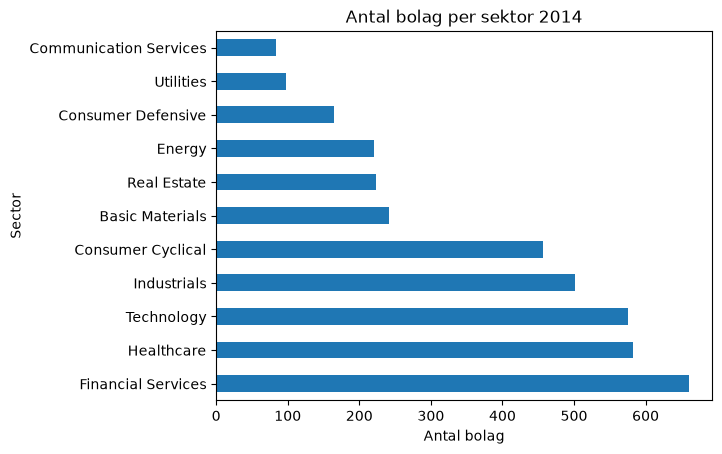

In [11]:
df["Sector"].value_counts().plot(kind="barh")
plt.title("Antal bolag per sektor 2014")
plt.xlabel("Antal bolag")
plt.show()

In [12]:
df.groupby("Sector")["2015 PRICE VAR [%]"].median().sort_values().round(1)

Sector
Energy                   -33.7
Basic Materials          -22.7
Industrials              -13.8
Consumer Cyclical         -6.1
Communication Services    -5.3
Technology                -4.8
Healthcare                -4.1
Utilities                 -2.5
Real Estate               -2.3
Consumer Defensive         2.8
Financial Services         5.5
Name: 2015 PRICE VAR [%], dtype: float64

### Energy föll cirka 34 % medan Financial Services steg. Sektor påverkar avkastningen mycket.

## Del 4: Målvariabel

In [13]:
median_return = df["2015 PRICE VAR [%]"].median()
print(f"Medianavkastning 2015: {median_return:.2f} %")

df["above_median"] = (df["2015 PRICE VAR [%]"] > median_return).astype(int)
df["above_median"].value_counts()

Medianavkastning 2015: -5.28 %


above_median
0    1904
1    1904
Name: count, dtype: int64

In [14]:
pd.crosstab(df["Class"], df["above_median"])

above_median,0,1
Class,,
0,1904,270
1,0,1634


### 270 aktier har Class = 0 (de föll) men hamnar ändå över medianen, eftersom de föll mindre än −5,28 %. Class och vår målvariabel är alltså inte samma sak.

## Slutsatser inför datarensningen

- 186 bolag saknar mer än hälften av sina värden.
- Det finns orimliga avkastningsvärden som troligen är datafel.
- P/E sätts till 0 för bolag med förlust, vilket behöver hanteras.
- Avkastningen skiljer sig mycket mellan sektorer.
- Målvariabeln above_median är skapad. Class-kolumnen ska inte användas som feature.